In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

plt.rcParams['font.sans-serif'] = ['Tahoma', 'DejaVu Sans', 'Arial']
plt.rcParams['axes.unicode_minus'] = False
sns.set_theme(style='whitegrid', font_scale=0.95)
pd.set_option('display.width', 160)

ALPHA = 0.05


GITHUB_RAW = 'https://raw.githubusercontent.com/NattapatJarounsup/DataSci-ClimateChange/main/'
CANDIDATE_DIRS = ['.', '..', '/content', '/content/drive/MyDrive/DS PROJ101']

def data_path(fname):
    for d in CANDIDATE_DIRS:
        if os.path.exists(os.path.join(d, fname)):
            return os.path.join(d, fname)
    return GITHUB_RAW + fname


FLOOD_PATH, BUDGET_PATH = data_path('bkk_flood_50_districts.csv'), data_path('bkk_budget_by_project.csv')
print('Loading:', FLOOD_PATH, '|', BUDGET_PATH)
flood_df = pd.read_csv(FLOOD_PATH, thousands=',')
budget_df = pd.read_csv(BUDGET_PATH, thousands=',')

Loading: https://raw.githubusercontent.com/NattapatJarounsup/DataSci-ClimateChange/main/bkk_flood_50_districts.csv | https://raw.githubusercontent.com/NattapatJarounsup/DataSci-ClimateChange/main/bkk_budget_by_project.csv


In [2]:

thai_to_eng_districts = {
    'คลองสาน': 'Khlong San', 'คลองสามวา': 'Khlong Sam Wa', 'คลองเตย': 'Khlong Toei', 'คันนายาว': 'Khan Na Yao',
    'จตุจักร': 'Chatuchak', 'จอมทอง': 'Chom Thong', 'ดอนเมือง': 'Don Mueang', 'ดินแดง': 'Din Daeng',
    'ดุสิต': 'Dusit', 'ตลิ่งชัน': 'Taling Chan', 'ทวีวัฒนา': 'Thawi Watthana', 'ทุ่งครุ': 'Thung Khru',
    'ธนบุรี': 'Thon Buri', 'บางกะปิ': 'Bang Kapi', 'บางกอกน้อย': 'Bangkok Noi', 'บางกอกใหญ่': 'Bangkok Yai',
    'บางขุนเทียน': 'Bang Khun Thian', 'บางคอแหลม': 'Bang Kho Laem', 'บางซื่อ': 'Bang Sue', 'บางนา': 'Bang Na',
    'บางบอน': 'Bang Bon', 'บางพลัด': 'Bang Phlat', 'บางรัก': 'Bang Rak', 'บางเขน': 'Bang Khen',
    'บางแค': 'Bang Khae', 'บึงกุ่ม': 'Bueng Kum', 'ปทุมวัน': 'Pathum Wan', 'ประเวศ': 'Prawet',
    'ป้อมปราบศัตรูพ่าย': 'Pom Prap Sattru Phai', 'พญาไท': 'Phaya Thai', 'พระนคร': 'Phra Nakhon',
    'พระโขนง': 'Phra Khanong', 'ภาษีเจริญ': 'Phasi Charoen', 'มีนบุรี': 'Min Buri', 'ยานนาวา': 'Yan Nawa',
    'ราชเทวี': 'Ratchathewi', 'ราษฎร์บูรณะ': 'Rat Burana', 'ลาดกระบัง': 'Lat Krabang', 'ลาดพร้าว': 'Lat Phrao',
    'วังทองหลาง': 'Wang Thonglang', 'วัฒนา': 'Watthana', 'สวนหลวง': 'Suan Luang', 'สะพานสูง': 'Saphan Sung',
    'สัมพันธวงศ์': 'Samphanthawong', 'สาทร': 'Sathon', 'สายไหม': 'Sai Mai', 'หนองจอก': 'Nong Chok',
    'หนองแขม': 'Nong Khaem', 'หลักสี่': 'Lak Si', 'ห้วยขวาง': 'Huai Khwang'}
thai_to_eng_zones = {
    'กรุงเทพเหนือ': 'North BKK', 'กรุงเทพใต้': 'South BKK', 'กรุงเทพกลาง': 'Central BKK',
    'กรุงเทพตะวันออก': 'East BKK', 'กรุงธนเหนือ': 'North Thonburi', 'กรุงธนใต้': 'South Thonburi'}
project_group_map = {
    'เขื่อนและแนวป้องกันน้ำท่วม/แก้มลิง': 'Floodwalls, Dams & Retention Ponds',
    'อุโมงค์ ท่อระบายน้ำ และขุดลอกคลอง': 'Tunnels, Drain Pipes & Canal Dredging',
    'งบดำเนินงานและบำรุงรักษาทั่วไป': 'General Operations & Maintenance',
    'สถานีสูบน้ำ บ่อสูบน้ำ และประตูระบายน้ำ': 'Pumping Stations, Sumps & Floodgates',
    'จัดซื้อเครื่องสูบน้ำ ยานพาหนะ และอุปกรณ์': 'Pumps, Vehicles & Equipment Procurement',
    'ระบบตรวจวัดและศูนย์ควบคุมน้ำท่วม': 'Monitoring Systems & Flood Control Center'}


df = flood_df.rename(columns={
    'total_budget (MB)': 'budget_mb', 'flood_count': 'flood_count',
    'total_rainfall (mm)': 'total_rain_mm', 'avg_rainfall (mm)': 'avg_rain_mm',
    'total_drain_time (min)': 'total_drain_min', 'avg_drain_time (min)': 'avg_drain_min',
    'budget_per_flood (MB)': 'budget_per_flood_mb'}).copy()
df['drainage_dept_mb'] = df['budget_drainge_dept (THB)'] / 1e6
df['district_office_mb'] = df['budget_district_office (THB)'] / 1e6
df['district_en'] = df['district'].map(thai_to_eng_districts).fillna(df['district'])
df['zone_en'] = df['bkk_zone'].map(thai_to_eng_zones).fillna(df['bkk_zone'])
budget_df['project_group_en'] = budget_df['project_group'].map(project_group_map).fillna(budget_df['project_group'])

recorded = df[df['flood_record_status'] == 'Recorded'].copy()   # 39 เขตที่มีบันทึกน้ำท่วมบนถนนหลัก

NUM_COLS = ['budget_mb', 'drainage_dept_mb', 'district_office_mb', 'flood_count',
            'avg_rain_mm', 'avg_drain_min', 'budget_per_flood_mb']

def decide(p, alpha=ALPHA):

            else f'p = {p:.4f} > {alpha} -> Fail to reject H0 (หลักฐานไม่พอจะสรุปว่าต่าง/สัมพันธ์)')

def iqr_outliers(s):
    q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return lo, hi, s[(s < lo) | (s > hi)]

In [3]:
print('flood_df  :', flood_df.shape, '| budget_df :', budget_df.shape)
print('\nMissing values (flood_df):')
print(df[NUM_COLS].isna().sum())
print('\nflood_record_status:')
print(df['flood_record_status'].value_counts())
print('\nจำนวนเขตต่อกลุ่มเขต:')
print(df['zone_en'].value_counts())
print('\nงบรายโครงการ แยกระดับ/แหล่งงบ (ล้านบาท):')
print(budget_df.groupby(['budget_level', 'source'])['budget_mb'].agg(['count', 'sum']).round(2))

flood_df  : (50, 13) | budget_df : (251, 9)

Missing values (flood_df):
budget_mb               0
drainage_dept_mb        0
district_office_mb      0
flood_count             0
avg_rain_mm            11
avg_drain_min          11
budget_per_flood_mb    11
dtype: int64

flood_record_status:
flood_record_status
Recorded               39
No Main-Road Record    11
Name: count, dtype: int64

จำนวนเขตต่อกลุ่มเขต:
zone_en
South BKK         10
East BKK           9
Central BKK        9
North Thonburi     8
North BKK          7
South Thonburi     7
Name: count, dtype: int64

งบรายโครงการ แยกระดับ/แหล่งงบ (ล้านบาท):
                                 count      sum
budget_level source                            
Central      งบสำนักการระบายน้ำ     19   719.95
District     งบสำนักการระบายน้ำ    118  3800.70
             งบสำนักงานเขต         114   789.19


In [4]:
desc = df[NUM_COLS].describe().T
desc['median'] = df[NUM_COLS].median()
desc['IQR'] = desc['75%'] - desc['25%']
desc['skew'] = df[NUM_COLS].skew()
desc['kurtosis'] = df[NUM_COLS].kurt()
desc['shapiro_p'] = [stats.shapiro(df[c].dropna()).pvalue for c in NUM_COLS]
desc[['count', 'mean', 'median', 'std', 'min', '25%', '75%', 'max', 'IQR', 'skew', 'kurtosis', 'shapiro_p']].round(3)

,count,mean,median,std,min,25%,75%,max,IQR,skew,kurtosis,shapiro_p
budget_mb,50.0,91.795,65.305,102.737,1.150,18.342,136.185,563.500,117.842,2.262,7.866,0.000
drainage_dept_mb,50.0,76.012,52.519,100.460,0.000,5.579,119.613,558.489,114.034,2.588,9.869,0.000
district_office_mb,50.0,15.783,5.250,30.765,1.147,3.728,18.303,209.410,14.576,5.341,33.096,0.000
flood_count,50.0,12.560,7.000,13.048,0.000,1.250,20.000,44.000,18.750,0.793,-0.621,0.000
avg_rain_mm,39.0,70.974,72.000,14.410,38.000,61.000,78.500,95.000,17.500,-0.346,-0.130,0.315
avg_drain_min,39.0,132.956,104.020,78.620,25.000,86.080,177.955,431.670,91.875,1.631,4.181,0.001
budget_per_flood_mb,39.0,12.154,5.830,16.912,0.190,1.770,12.505,71.760,10.735,2.418,5.941,0.000


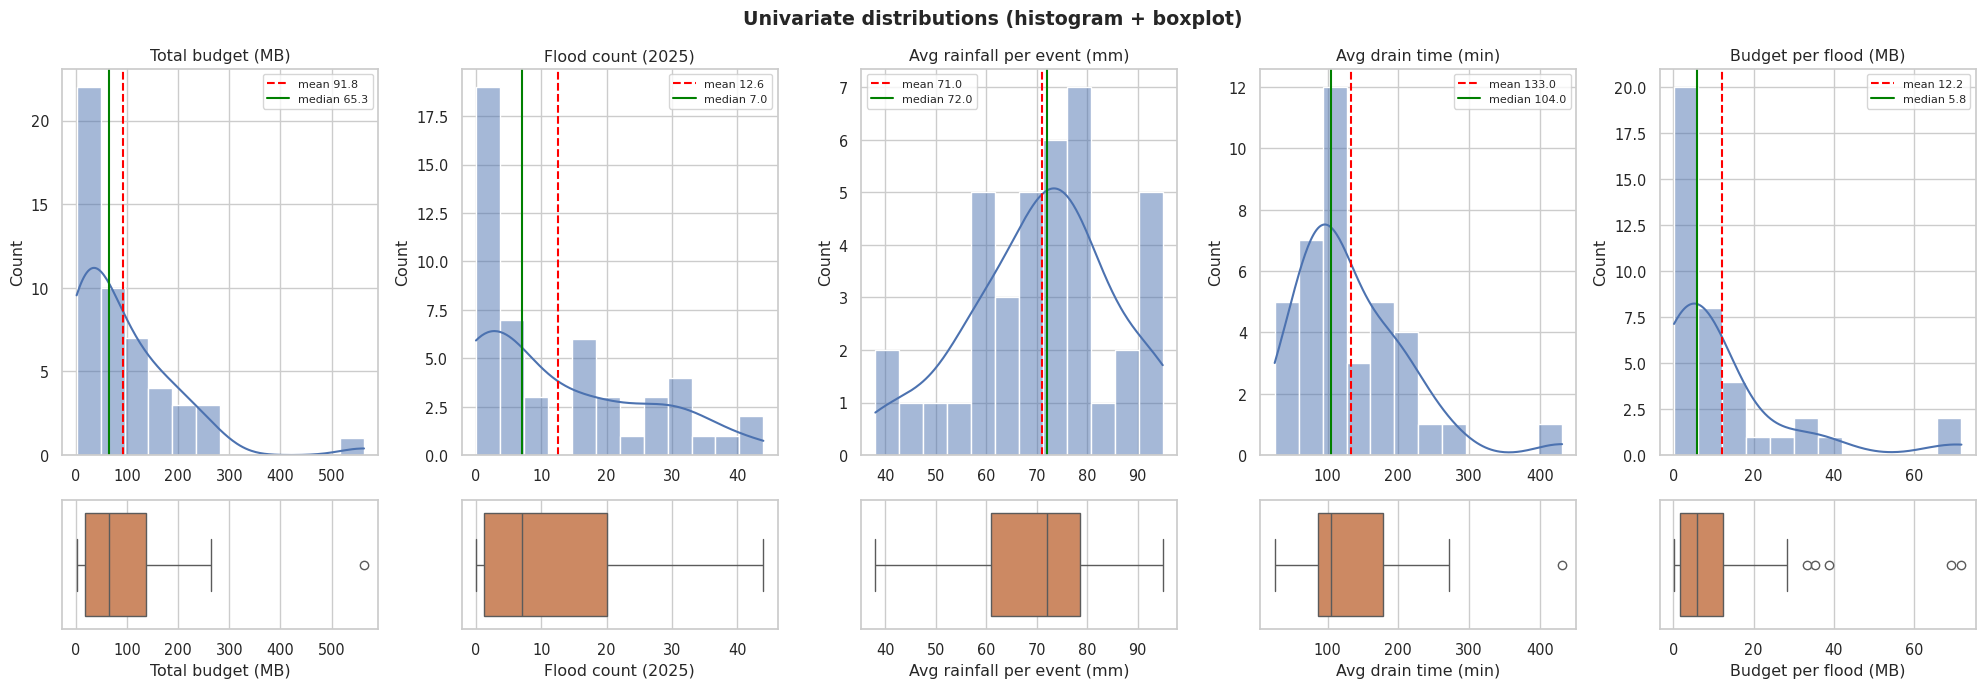

In [5]:
plot_cols = ['budget_mb', 'flood_count', 'avg_rain_mm', 'avg_drain_min', 'budget_per_flood_mb']
labels = ['Total budget (MB)', 'Flood count (2025)', 'Avg rainfall per event (mm)',
          'Avg drain time (min)', 'Budget per flood (MB)']
fig, axes = plt.subplots(2, len(plot_cols), figsize=(20, 7), gridspec_kw={'height_ratios': [3, 1]})
for i, (c, lab) in enumerate(zip(plot_cols, labels)):
    s = df[c].dropna()
    sns.histplot(s, bins=12, kde=True, ax=axes[0, i], color='#4C72B0')
    axes[0, i].axvline(s.mean(), color='red', ls='--', label=f'mean {s.mean():.1f}')
    axes[0, i].axvline(s.median(), color='green', ls='-', label=f'median {s.median():.1f}')
    axes[0, i].set_title(lab); axes[0, i].legend(fontsize=8); axes[0, i].set_xlabel('')
    sns.boxplot(x=s, ax=axes[1, i], color='#DD8452'); axes[1, i].set_xlabel(lab)
plt.suptitle('Univariate distributions (histogram + boxplot)', weight='bold')
plt.tight_layout(); plt.show()

In [6]:

for c in ['budget_mb', 'flood_count', 'avg_drain_min', 'budget_per_flood_mb']:
    lo, hi, out = iqr_outliers(df[c].dropna())
    names = df.loc[out.index, ['district_en', c]].sort_values(c, ascending=False)
    print(f'{c:22s} fence = [{lo:8.2f}, {hi:8.2f}]  outliers: ' +
          (', '.join(f'{r.district_en} ({r[c]:.2f})' for _, r in names.iterrows()) or '-'))

budget_mb              fence = [ -158.42,   312.95]  outliers: Suan Luang (563.50)
flood_count            fence = [  -26.88,    48.12]  outliers: -
avg_drain_min          fence = [  -51.73,   315.77]  outliers: Don Mueang (431.67)
budget_per_flood_mb    fence = [  -14.33,    28.61]  outliers: Dusit (71.76), Yan Nawa (69.09), Bangkok Noi (38.78), Suan Luang (35.22), Bangkok Yai (33.21)


All 50 districts : Pearson r = 0.277 (p = 0.0515 > 0.05 -> Fail to reject H0 (หลักฐานไม่พอจะสรุปว่าต่าง/สัมพันธ์))
All 50 districts : Spearman rho = 0.368 (p = 0.0085 <= 0.05 -> Reject H0 (มีนัยสำคัญทางสถิติ))
Recorded 39 only : Spearman rho = 0.342 (p = 0.0329 <= 0.05 -> Reject H0 (มีนัยสำคัญทางสถิติ))


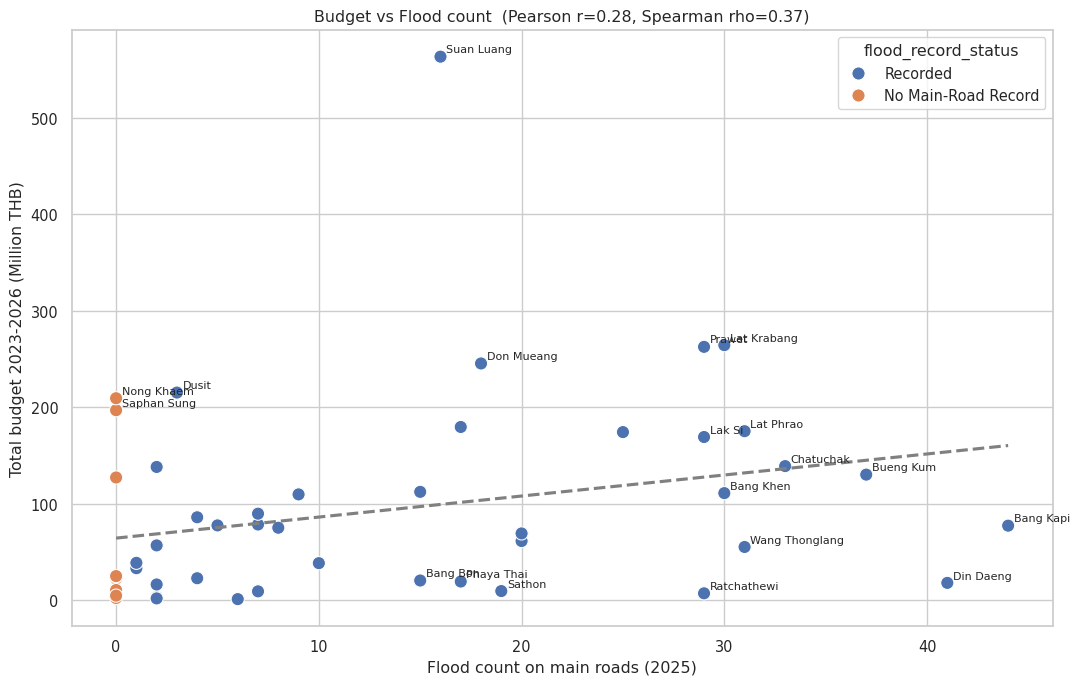

In [7]:
pear = stats.pearsonr(df['budget_mb'], df['flood_count'])
spear = stats.spearmanr(df['budget_mb'], df['flood_count'])
spear_rec = stats.spearmanr(recorded['budget_mb'], recorded['flood_count'])
print(f'All 50 districts : Pearson r = {pear.statistic:.3f} ({decide(pear.pvalue)})')
print(f'All 50 districts : Spearman rho = {spear.statistic:.3f} ({decide(spear.pvalue)})')
print(f'Recorded 39 only : Spearman rho = {spear_rec.statistic:.3f} ({decide(spear_rec.pvalue)})')

fig, ax = plt.subplots(figsize=(11, 7))
sns.regplot(data=df, x='flood_count', y='budget_mb', ax=ax, scatter=False, color='grey', ci=None, line_kws={'ls': '--'})
sns.scatterplot(data=df, x='flood_count', y='budget_mb', hue='flood_record_status', s=90, ax=ax)
for _, r in df.iterrows():
    if r['budget_mb'] > 180 or r['flood_count'] >= 28 or (r['flood_count'] >= 15 and r['budget_mb'] < 25):
        ax.annotate(r['district_en'], (r['flood_count'], r['budget_mb']), fontsize=8, xytext=(4, 3), textcoords='offset points')
ax.set_title(f'Budget vs Flood count  (Pearson r={pear.statistic:.2f}, Spearman rho={spear.statistic:.2f})')
ax.set_xlabel('Flood count on main roads (2025)'); ax.set_ylabel('Total budget 2023-2026 (Million THB)')
plt.tight_layout(); plt.show()

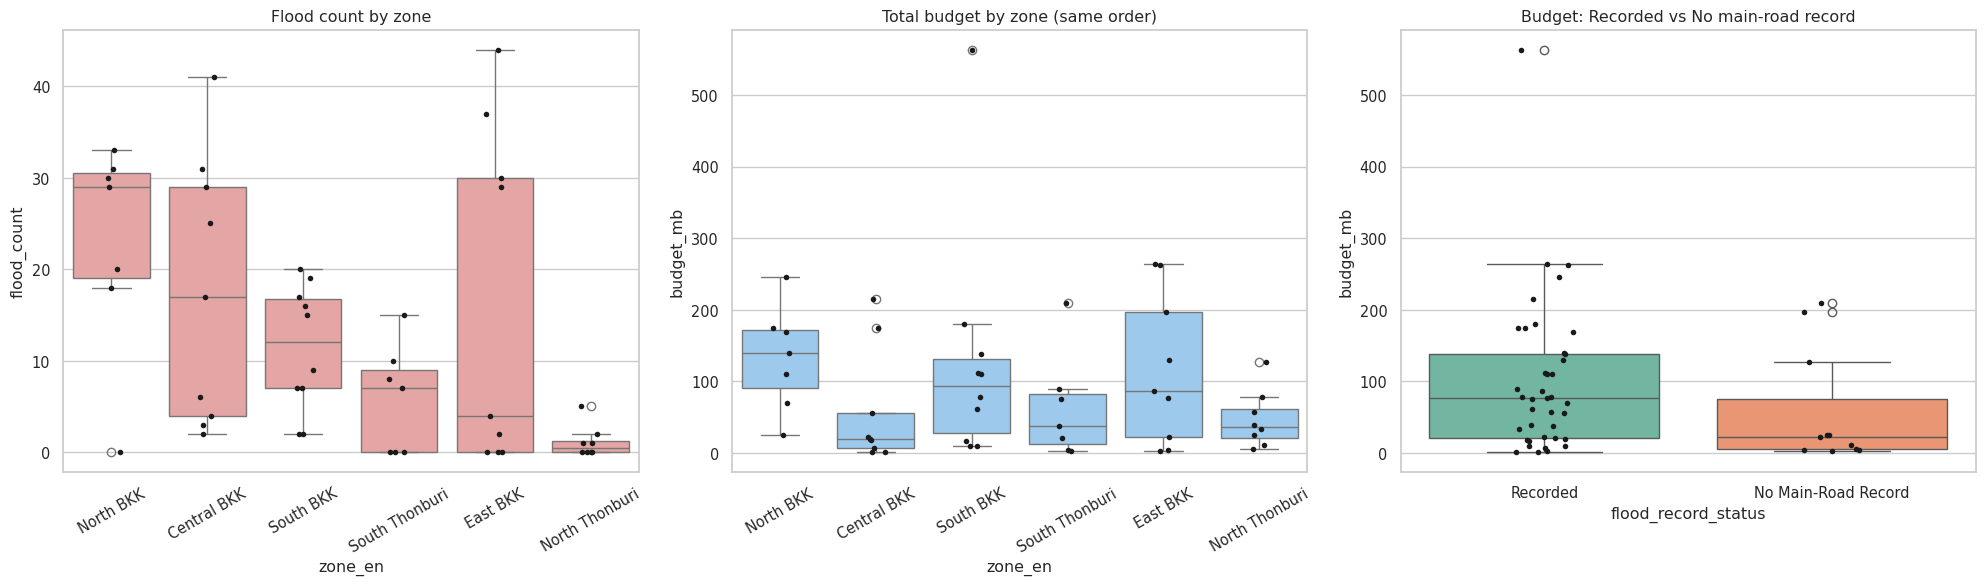

               flood_count        budget_mb       
                       sum median       sum median
zone_en                                           
Central BKK            158   17.0     515.2   19.4
East BKK               146    4.0    1048.0   86.0
North BKK              161   29.0     934.0  139.0
North Thonburi           9    0.5     375.1   36.0
South BKK              114   12.0    1278.3   94.1
South Thonburi          40    7.0     439.2   38.4


In [8]:
fig, axes = plt.subplots(1, 3, figsize=(20, 6))
order = df.groupby('zone_en')['flood_count'].median().sort_values(ascending=False).index
sns.boxplot(data=df, x='zone_en', y='flood_count', order=order, ax=axes[0], color='#EF9A9A')
sns.stripplot(data=df, x='zone_en', y='flood_count', order=order, ax=axes[0], color='k', size=4)
axes[0].set_title('Flood count by zone'); axes[0].tick_params(axis='x', rotation=30)
sns.boxplot(data=df, x='zone_en', y='budget_mb', order=order, ax=axes[1], color='#90CAF9')
sns.stripplot(data=df, x='zone_en', y='budget_mb', order=order, ax=axes[1], color='k', size=4)
axes[1].set_title('Total budget by zone (same order)'); axes[1].tick_params(axis='x', rotation=30)
sns.boxplot(data=df, x='flood_record_status', y='budget_mb', ax=axes[2], palette='Set2', hue='flood_record_status', legend=False)
sns.stripplot(data=df, x='flood_record_status', y='budget_mb', ax=axes[2], color='k', size=4)
axes[2].set_title('Budget: Recorded vs No main-road record')
plt.tight_layout(); plt.show()
print(df.groupby('zone_en')[['flood_count', 'budget_mb']].agg(['sum', 'median']).round(1))

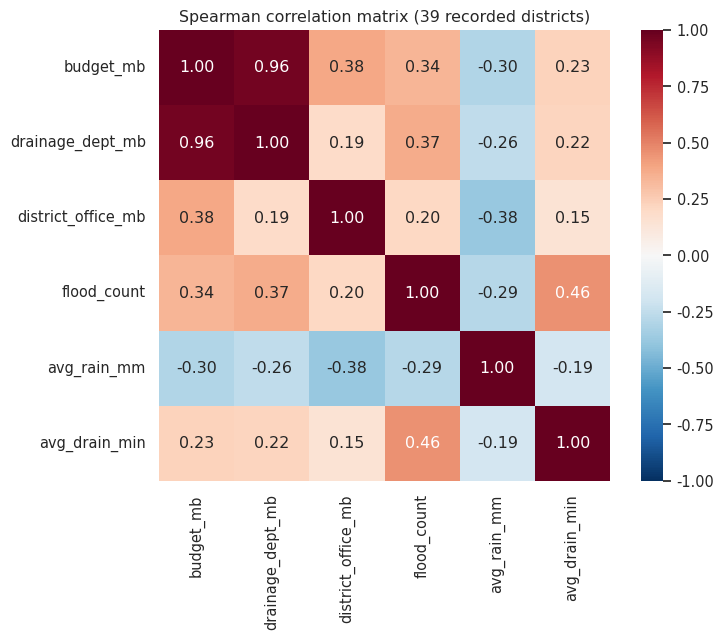

drainage_dept_mb     vs flood_count    : rho = +0.368  p = 0.0211 <= 0.05 -> Reject H0 (มีนัยสำคัญทางสถิติ)
district_office_mb   vs flood_count    : rho = +0.203  p = 0.2147 > 0.05 -> Fail to reject H0 (หลักฐานไม่พอจะสรุปว่าต่าง/สัมพันธ์)
flood_count          vs avg_drain_min  : rho = +0.458  p = 0.0034 <= 0.05 -> Reject H0 (มีนัยสำคัญทางสถิติ)
avg_rain_mm          vs flood_count    : rho = -0.285  p = 0.0782 > 0.05 -> Fail to reject H0 (หลักฐานไม่พอจะสรุปว่าต่าง/สัมพันธ์)


In [9]:
corr_cols = ['budget_mb', 'drainage_dept_mb', 'district_office_mb', 'flood_count', 'avg_rain_mm', 'avg_drain_min']
corr = recorded[corr_cols].corr(method='spearman')
fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu_r', vmin=-1, vmax=1, square=True, ax=ax)
ax.set_title('Spearman correlation matrix (39 recorded districts)')
plt.tight_layout(); plt.show()

for x, y in [('drainage_dept_mb', 'flood_count'), ('district_office_mb', 'flood_count'),
             ('flood_count', 'avg_drain_min'), ('avg_rain_mm', 'flood_count')]:
    r = stats.spearmanr(recorded[x], recorded[y])
    print(f'{x:20s} vs {y:15s}: rho = {r.statistic:+.3f}  {decide(r.pvalue)}')

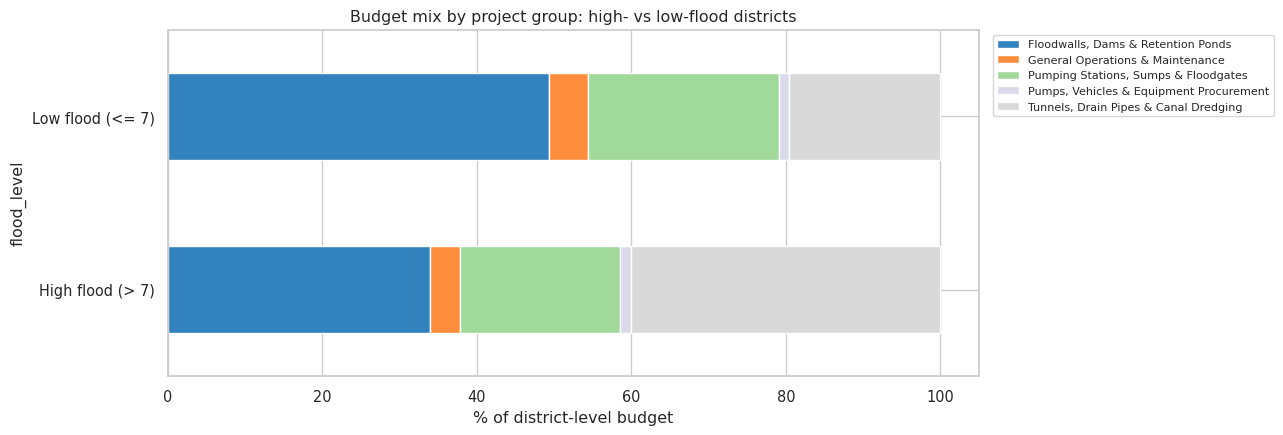

flood_level,High flood (> 7),Low flood (<= 7)
project_group_en,,
"Floodwalls, Dams & Retention Ponds",34.0,49.4
General Operations & Maintenance,3.8,5.0
"Pumping Stations, Sumps & Floodgates",20.8,24.7
"Pumps, Vehicles & Equipment Procurement",1.4,1.2
"Tunnels, Drain Pipes & Canal Dredging",40.0,19.6


In [10]:

median_flood = df['flood_count'].median()
proj = budget_df[budget_df['budget_level'] == 'District'].merge(df[['district', 'flood_count']], on='district')
proj['flood_level'] = np.where(proj['flood_count'] > median_flood,
                               f'High flood (> {median_flood:.0f})', f'Low flood (<= {median_flood:.0f})')
share = proj.pivot_table(index='flood_level', columns='project_group_en', values='budget_mb', aggfunc='sum', fill_value=0)
share_pct = share.div(share.sum(axis=1), axis=0) * 100
ax = share_pct.plot(kind='barh', stacked=True, figsize=(13, 4.5), colormap='tab20c')
ax.set_xlabel('% of district-level budget'); ax.set_title('Budget mix by project group: high- vs low-flood districts')
ax.legend(bbox_to_anchor=(1.01, 1), loc='upper left', fontsize=8); plt.tight_layout(); plt.show()
share_pct.round(1).T

In [11]:
results = []
def log(name, h0, test, stat, p):
    results.append({'Question': name, 'H0': h0, 'Test': test, 'Statistic': round(stat, 3),
                    'p-value': round(p, 4), 'Decision': 'Reject H0' if p <= ALPHA else 'Fail to reject H0'})


r = stats.spearmanr(df['budget_mb'], df['flood_count'])
log('Budget related to flood count?', 'rho = 0', 'Spearman (n=50)', r.statistic, r.pvalue)
r = stats.pearsonr(df['budget_mb'], df['flood_count'])
log('Budget related to flood count?', 'r = 0', 'Pearson (n=50)', r.statistic, r.pvalue)


groups_f = [g['flood_count'].values for _, g in df.groupby('zone_en')]
a = stats.f_oneway(*groups_f); k = stats.kruskal(*groups_f)
log('Flood count differs by zone?', 'mu equal across 6 zones', 'One-way ANOVA', a.statistic, a.pvalue)
log('Flood count differs by zone?', 'same distribution', 'Kruskal-Wallis', k.statistic, k.pvalue)


groups_b = [g['budget_mb'].values for _, g in df.groupby('zone_en')]
a = stats.f_oneway(*groups_b); k = stats.kruskal(*groups_b)
log('Budget differs by zone?', 'mu equal across 6 zones', 'One-way ANOVA', a.statistic, a.pvalue)
log('Budget differs by zone?', 'same distribution', 'Kruskal-Wallis', k.statistic, k.pvalue)


rec = df.loc[df['flood_record_status'] == 'Recorded', 'budget_mb']
norec = df.loc[df['flood_record_status'] != 'Recorded', 'budget_mb']
t = stats.ttest_ind(rec, norec, equal_var=False); u = stats.mannwhitneyu(rec, norec)
log('Budget: Recorded vs No record?', 'mu1 = mu2', 'Welch t-test', t.statistic, t.pvalue)
log('Budget: Recorded vs No record?', 'same distribution', 'Mann-Whitney U', u.statistic, u.pvalue)


t = stats.ttest_rel(df['drainage_dept_mb'], df['district_office_mb']); w = stats.wilcoxon(df['drainage_dept_mb'], df['district_office_mb'])
log('Drainage Dept vs District Office budget (paired)?', 'mean diff = 0', 'Paired t-test', t.statistic, t.pvalue)
log('Drainage Dept vs District Office budget (paired)?', 'median diff = 0', 'Wilcoxon signed-rank', w.statistic, w.pvalue)

print(f'Recorded mean = {rec.mean():.1f} MB (n={len(rec)}) | No record mean = {norec.mean():.1f} MB (n={len(norec)})')
print(f'Top-10 districts share: flood = {df.nlargest(10, "flood_count").flood_count.sum() / df.flood_count.sum():.1%}, budget = {df.nlargest(10, "budget_mb").budget_mb.sum() / df.budget_mb.sum():.1%}')
print(f'Drainage Dept mean = {df.drainage_dept_mb.mean():.1f} MB | District Office mean = {df.district_office_mb.mean():.1f} MB')
pd.DataFrame(results)

Recorded mean = 101.5 MB (n=39) | No record mean = 57.6 MB (n=11)
Top-10 districts share: flood = 53.3%, budget = 54.2%
Drainage Dept mean = 76.0 MB | District Office mean = 15.8 MB


,Question,H0,Test,Statistic,p-value,Decision
0,Budget related to flood count?,rho = 0,Spearman (n=50),0.368,0.0085,Reject H0
1,Budget related to flood count?,r = 0,Pearson (n=50),0.277,0.0515,Fail to reject H0
2,Flood count differs by zone?,mu equal across 6 zones,One-way ANOVA,3.757,0.0064,Reject H0
3,Flood count differs by zone?,same distribution,Kruskal-Wallis,15.857,0.0073,Reject H0
4,Budget differs by zone?,mu equal across 6 zones,One-way ANOVA,1.229,0.3119,Fail to reject H0
5,Budget differs by zone?,same distribution,Kruskal-Wallis,7.636,0.1774,Fail to reject H0
6,Budget: Recorded vs No record?,mu1 = mu2,Welch t-test,1.480,0.1536,Fail to reject H0
7,Budget: Recorded vs No record?,same distribution,Mann-Whitney U,285.000,0.1011,Fail to reject H0
8,Drainage Dept vs District Office budget (paired)?,mean diff = 0,Paired t-test,3.968,0.0002,Reject H0
9,Drainage Dept vs District Office budget (paired)?,median diff = 0,Wilcoxon signed-rank,201.000,0.0000,Reject H0


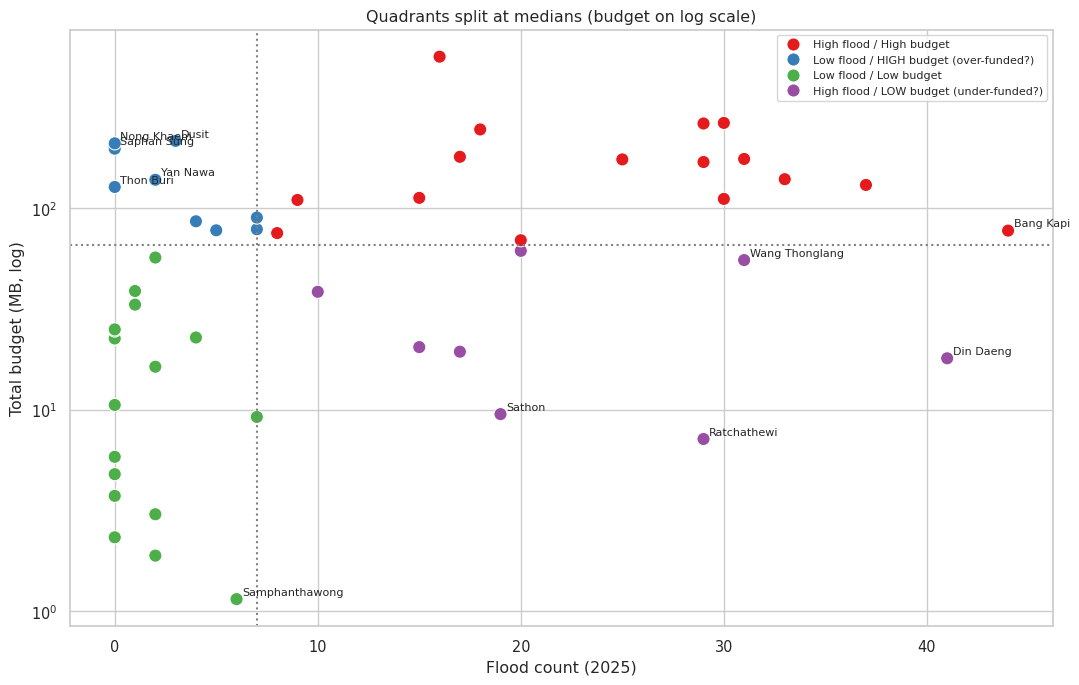

quadrant
Low flood / Low budget                     17
High flood / High budget                   16
Low flood / HIGH budget (over-funded?)      9
High flood / LOW budget (under-funded?)     8
Name: count, dtype: int64 

Top 6 "flooded more than funded":
   district_en     zone_en  flood_count  budget_mb  avg_drain_min  rank_gap
     Din Daeng Central BKK           41      17.99         104.02      0.72
   Ratchathewi Central BKK           29       7.16          84.66      0.66
        Sathon   South BKK           19       9.51          77.11      0.52
Wang Thonglang Central BKK           31      55.22         209.74      0.45
Samphanthawong Central BKK            6       1.15          66.67      0.44
     Bang Kapi    East BKK           44      77.31         188.14      0.44

Top 6 "funded more than flooded":
district_en        zone_en  flood_count  budget_mb  avg_drain_min  rank_gap
 Nong Khaem South Thonburi            0     209.41            NaN     -0.78
Saphan Sung       East BKK

In [12]:
median_budget = df['budget_mb'].median()
df['quadrant'] = np.select(
    [(df.flood_count > median_flood) & (df.budget_mb > median_budget),
     (df.flood_count > median_flood) & (df.budget_mb <= median_budget),
     (df.flood_count <= median_flood) & (df.budget_mb > median_budget)],
    ['High flood / High budget', 'High flood / LOW budget (under-funded?)', 'Low flood / HIGH budget (over-funded?)'],
    default='Low flood / Low budget')

df['rank_gap'] = df['flood_count'].rank(pct=True) - df['budget_mb'].rank(pct=True)

fig, ax = plt.subplots(figsize=(11, 7))
sns.scatterplot(data=df, x='flood_count', y='budget_mb', hue='quadrant', s=90, ax=ax, palette='Set1')
ax.axvline(median_flood, color='grey', ls=':'); ax.axhline(median_budget, color='grey', ls=':')
ax.set_yscale('log')
for _, r in df.iterrows():
    if abs(r['rank_gap']) >= 0.4:
        ax.annotate(r['district_en'], (r['flood_count'], r['budget_mb']), fontsize=8, xytext=(4, 3), textcoords='offset points')
ax.set_title('Quadrants split at medians (budget on log scale)')
ax.set_xlabel('Flood count (2025)'); ax.set_ylabel('Total budget (MB, log)')
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

print(df['quadrant'].value_counts(), '\n')
cols = ['district_en', 'zone_en', 'flood_count', 'budget_mb', 'avg_drain_min', 'rank_gap']
print('Top 6 "flooded more than funded":'); print(df.nlargest(6, 'rank_gap')[cols].round(2).to_string(index=False))
print('\nTop 6 "funded more than flooded":'); print(df.nsmallest(6, 'rank_gap')[cols].round(2).to_string(index=False))

In [13]:

import geopandas as gpd
import folium
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
from matplotlib.colors import LogNorm, TwoSlopeNorm

GEOJSON_URL = 'https://raw.githubusercontent.com/pcrete/gsvloader-demo/master/geojson/Bangkok-districts.geojson'
geo = gpd.read_file(GEOJSON_URL)

geo['district'] = geo['dname'].str.replace('^เขต', '', regex=True).str.replace('ฏ', 'ฎ').str.strip()
gdf = geo[['district', 'AREA', 'geometry']].merge(df, on='district', how='inner', validate='one_to_one')
assert len(gdf) == 50, f'จับคู่ได้แค่ {len(gdf)} เขต'
gdf['area_km2'] = gdf['AREA'] / 1e6
gdf['flood_per_10km2'] = gdf['flood_count'] / gdf['area_km2'] * 10


thon = gdf[gdf['zone_en'].str.contains('Thonburi')].union_all()
phra = gdf[~gdf['zone_en'].str.contains('Thonburi')].union_all()
river = gpd.GeoSeries([thon.boundary.intersection(phra.boundary)], crs=gdf.crs)
zones = gdf.dissolve(by='zone_en')[['geometry']]
os.makedirs('figures', exist_ok=True)


gdf['label_pt'] = gdf.geometry.representative_point()
print('matched districts:', len(gdf), '| river length ≈', round(river.to_crs(32647).length.iloc[0] / 1000, 1), 'km')

matched districts: 50 | river length ≈ 20.9 km


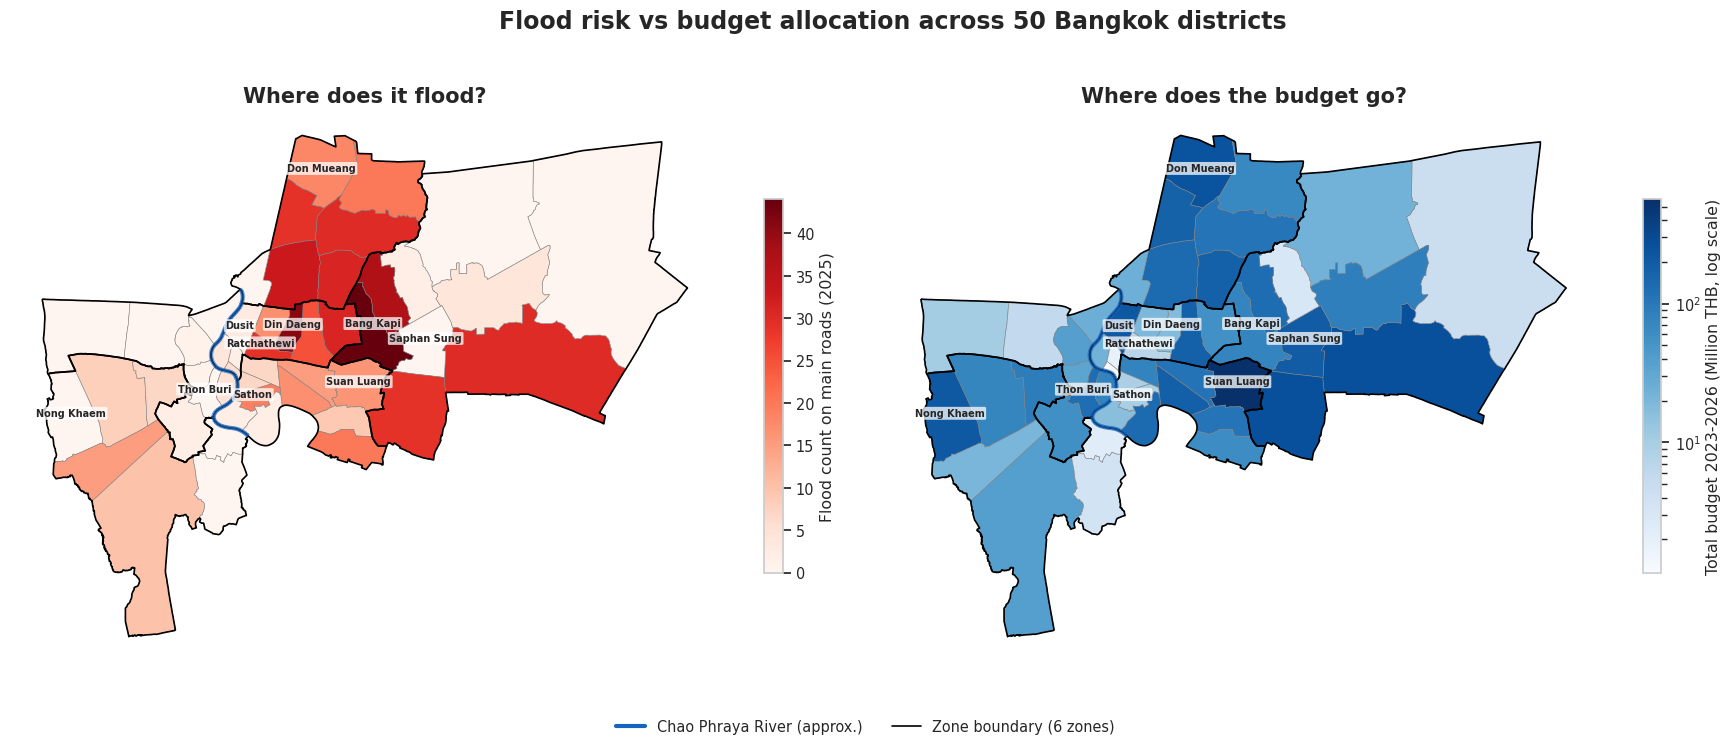

In [14]:
def base_layers(ax):
    zones.boundary.plot(ax=ax, color='black', linewidth=1.2)
    river.plot(ax=ax, color='#1565C0', linewidth=3, alpha=0.8)
    ax.set_axis_off()

def label(ax, names, col='district_en', size=7):
    for _, r in gdf[gdf[col].isin(names)].iterrows():
        ax.annotate(r[col], (r.label_pt.x, r.label_pt.y), ha='center', fontsize=size, weight='bold',
                    bbox=dict(boxstyle='round,pad=0.15', fc='white', ec='none', alpha=0.75))

key_names = ['Din Daeng', 'Ratchathewi', 'Sathon', 'Bang Kapi', 'Nong Khaem', 'Saphan Sung',
             'Suan Luang', 'Don Mueang', 'Dusit', 'Thon Buri']

fig, axes = plt.subplots(1, 2, figsize=(18, 7.5))
gdf.plot(column='flood_count', cmap='Reds', linewidth=0.4, edgecolor='grey', ax=axes[0], legend=True,
         legend_kwds={'label': 'Flood count on main roads (2025)', 'shrink': 0.6})
gdf.plot(column='budget_mb', cmap='Blues', norm=LogNorm(gdf.budget_mb.min(), gdf.budget_mb.max()),
         linewidth=0.4, edgecolor='grey', ax=axes[1], legend=True,
         legend_kwds={'label': 'Total budget 2023-2026 (Million THB, log scale)', 'shrink': 0.6})
for ax, t in zip(axes, ['Where does it flood?', 'Where does the budget go?']):
    base_layers(ax); label(ax, key_names); ax.set_title(t, fontsize=15, weight='bold')
fig.legend(handles=[Line2D([0], [0], color='#1565C0', lw=3, label='Chao Phraya River (approx.)'),
                    Line2D([0], [0], color='black', lw=1.2, label='Zone boundary (6 zones)')],
           loc='lower center', ncol=2, frameon=False)
plt.suptitle('Flood risk vs budget allocation across 50 Bangkok districts', fontsize=17, weight='bold')
plt.tight_layout(rect=[0, 0.04, 1, 0.97])
plt.savefig('figures/map_flood_vs_budget.png', dpi=200, bbox_inches='tight'); plt.show()

In [17]:
quad_colors = {
    'High flood / High budget': '#e41a1c',          # Red
    'High flood / LOW budget (under-funded?)': '#377eb8',  # Blue
    'Low flood / HIGH budget (over-funded?)': '#4daf4a',   # Green
    'Low flood / Low budget': '#984ea3'             # Purple
}

gj = gdf[['district', 'district_en', 'zone_en', 'flood_count', 'budget_mb', 'avg_drain_min',
          'quadrant', 'rank_gap', 'geometry']].copy()
gj['geometry'] = gj.geometry.simplify(0.0003, preserve_topology=True)
gj['budget_mb'] = gj['budget_mb'].round(1); gj['rank_gap'] = gj['rank_gap'].round(2)
gj['avg_drain_min'] = gj['avg_drain_min'].round(0).fillna(-1)


CARTO_API_KEY = ''
VOYAGER = 'https://{s}.basemaps.cartocdn.com/rastertiles/voyager/{z}/{x}/{y}{r}.png'
if CARTO_API_KEY:
    VOYAGER = 'https://basemaps.cartocdn.com/rastertiles/voyager/{z}/{x}/{y}.png?key=' + CARTO_API_KEY
m = folium.Map(location=[13.75, 100.6], zoom_start=11, tiles=None)
folium.TileLayer(VOYAGER, name='CARTO Voyager', control=False, max_zoom=20, subdomains='abcd',
                 attr='&copy; <a href="https://www.openstreetmap.org/copyright">OpenStreetMap</a> contributors &copy; <a href="https://carto.com/attributions">CARTO</a>').add_to(m)
tip = folium.GeoJsonTooltip(fields=['district', 'district_en', 'zone_en', 'flood_count', 'budget_mb', 'avg_drain_min', 'quadrant', 'rank_gap'],
                            aliases=['เขต', 'District', 'Zone', 'Flood count (2025)', 'Budget (MB)', 'Avg drain time (min, -1 = no record)', 'Group', 'Rank gap'])
folium.Choropleth(gj, data=gj, columns=['district', 'flood_count'], key_on='feature.properties.district',
                  fill_color='Reds', fill_opacity=0.75, line_opacity=0.4, name='Flood count', legend_name='Flood count (2025)').add_to(m)
folium.Choropleth(gj, data=gj.assign(log_budget=np.log10(gj.budget_mb)), columns=['district', 'log_budget'],
                  key_on='feature.properties.district', fill_color='Blues', fill_opacity=0.75, line_opacity=0.4,
                  name='Budget (log10 MB)', legend_name='Budget, log10(Million THB)', show=False).add_to(m)
folium.GeoJson(gj, name='Mismatch group', show=False,
               style_function=lambda f: {'fillColor': quad_colors.get(f['properties']['quadrant'], '#grey'), 'color': 'grey',
                                         'weight': 0.5, 'fillOpacity': 0.8}).add_to(m)
folium.GeoJson(gj, name='Hover info', tooltip=tip,
               style_function=lambda f: {'fillOpacity': 0, 'color': 'black', 'weight': 0.3}).add_to(m)
folium.GeoJson(river.simplify(0.0002).__geo_interface__, name='Chao Phraya (approx.)',
               style_function=lambda f: {'color': '#1565C0', 'weight': 4}).add_to(m)
folium.LayerControl(collapsed=False).add_to(m)
m.save('figures/bkk_flood_budget_map.html')
m